In [1]:
import numpy as np

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons
from particle_filter.plots.plot_EES import plot_ESS

from particle_filter.performance_metrics import RMSE, Interval_cover

C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:139: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:238: SyntaxWarning: invalid escape sequence '\;'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:292: SyntaxWarning: invalid escape sequence '\m'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:298: SyntaxWarning: invalid escape sequence '\h'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:309: SyntaxWarning: invalid escape sequence '\p'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:335: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_f

Ahora se quiere comparar el Bootstrap Particle Filter y el Auxiliary Particle Filter mediante un sistema no lineal.

El sistema es el siguiente:

- Ecuación estado:

$$
x_t = 0.5 \cdot x_{t-1} + \frac{25\cdot x_{t-1}}{1+x_{t-1}^2}+ w_t,\;\;\; w_t \sim \mathcal{N}(0, Q)
$$

- Ecuación de observación

$$
y_t = x_t + 0.05\cdot x_t^{2} + v_t,\;\;\; v_t \sim \mathcal{N}(0, R)
$$

### Variación del ruido de transición
En este primer apartado se deja fijo la matriz de covarianza de la ecuación de observación y se varía el valor de la matriz de covarianza del ruido de transición. La idea es observar si la influencia de tener una ecuación de transición que se va volviendo más incierta, implica un mejor rendimiento del Auxiliary Particle Filter (que hace uso de la observación) respecto al Bootstrap Particle Filter 

In [10]:
# Funcion de transicion y observación

def f(x):
    return (
        0.5 * x +
        25*x / (1 + x**2)
    )


def h(x):
    return x + 0.05 * (x ** 2)

In [115]:
# Definición del modelo de transición (fijo)
R = np.array([[1.]])

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [ ]:
import pickle

#--------------
# ONFIGURACIÓN
#--------------

# Longitud de la simulacion
T = 100

# Estado inicial
x0 = np.array([[0.0]])

# Valores matriz covarianza de transición
Q = [0.1, 1.0, 5.0, 7.5, 10.0]

# Numero de simulaciones
n_simulations = 10

# Numero ejecuciones filtro
n_runs = 10

# Numero de particulas
N = 100

#--------------
# RESULTADOS
#--------------
results_bpf = []
results_apf = []


for q in Q:

    # Definición modelo de transición
    noise_transition = GaussianNoise(q)
    transition = AdditiveTransitionModel(f, noise_transition)

    # Lista de simulaciones para Q
    q_results_bpf = []
    q_results_apf = []


    #---------------------------------------------
    # 'n_simulations' SIMULACIONES INDEPENDIENTES
    #---------------------------------------------

    for simulation in range(n_simulations):

        # Simulacion
        x_true, y_obs = system_simulation(transition, observation, x0, T)


        # Lista para 'n_runs' filtrados
        simulation_bpf = []
        simulation_apf = []


        #------------------------------
        # 'n_runs' EJECUCIONES FILTRO
        #------------------------------

        for run in range(n_runs):

            # Ejecucion Bootstrap Particle Filter
            bpf = BootstrapParticleFilter(N=N, transition_model=transition, observation_model=observation)
            bpf.initialize(mean=np.array([0.0]), cov = np.eye(1))
            est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N - 1))

            est_bpf["run"] = run
            simulation_bpf.append(est_bpf)

            # Ejecucion Auxiliary Particle Filter
            apf = AuxiliaryParticleFilter(N=N, transition_model=transition, observation_model=observation)
            apf.initialize(mean=np.array([0.0]), cov = np.eye(1))
            est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N - 1))

            est_apf["run"] = run
            simulation_apf.append(est_apf)


        #---------------------
        # GUARDAR SIMULACION
        #---------------------

        simulation_result_bpf = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_bpf
        }

        simulation_result_apf = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_apf
        }

        q_results_bpf.append(simulation_result_bpf)
        q_results_apf.append(simulation_result_apf)


    #-------------------------------
    # GUARDAR RESULTADOS DE ESTE Q
    #-------------------------------
    
    results_bpf.append(q_results_bpf)
    results_apf.append(q_results_apf)

    print(f"Matriz {q} finalizado")        


#-------------------------------
# GUARDAR RESULTADOS DE ESTE Q
#-------------------------------

with open("results_bpf.pkl", "wb") as file:
    pickle.dump(results_bpf, file)

with open("results_apf.pkl", "wb") as file:
    pickle.dump(results_apf, file)



Matriz 0.1 finalizado
Matriz 1.0 finalizado
Matriz 5.0 finalizado
Matriz 7.5 finalizado
Matriz 10.0 finalizado


In [3]:
# Importar resultados
import pickle

with open('results_bpf_exp1.pkl', 'rb') as file:
    results_bpf = pickle.load(file)

with open('results_apf_exp1.pkl', 'rb') as file:
    results_apf = pickle.load(file)

In [4]:
from functions_experiment1 import calculate_rmse, calculate_loglikelihood, calculate_mean_ess, calculate_mean_IC

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (RMSE)'}, xlabel='Q', ylabel='RMSE'>)

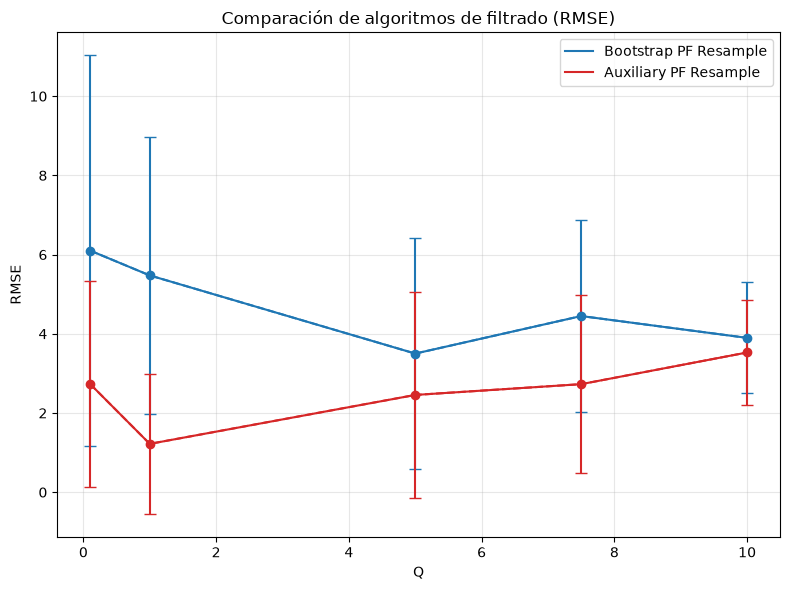

In [5]:
Q = [0.1, 1.0, 5.0, 7.5, 10.0]

rmse_bpf, rmse_bpf_sim = calculate_rmse(results_bpf)
rmse_apf, rmse_apf_sim = calculate_rmse(results_apf)

# Media de 'n_simulations' para cada q
res_rmse_bpf = [ np.mean(rmse_bpf_sim[q]) for q in Q]
res_rmse_apf = [ np.mean(rmse_apf_sim[q]) for q in Q]

# STD para cada q
std_rmse_bpf = [np.std(rmse_bpf_sim[q], ddof=1) for q in Q]
std_rmse_apf = [np.std(rmse_apf_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "Q": Q, "RMSE": res_rmse_bpf, "RMSE_errorbars": std_rmse_bpf }, 
        "Auxiliary PF Resample": { "Q": Q, "RMSE": res_rmse_apf, "RMSE_errorbars": std_rmse_apf }, 
    }, "Q", "RMSE", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (Loglikelihood)'}, xlabel='Q', ylabel='Loglikelihood'>)

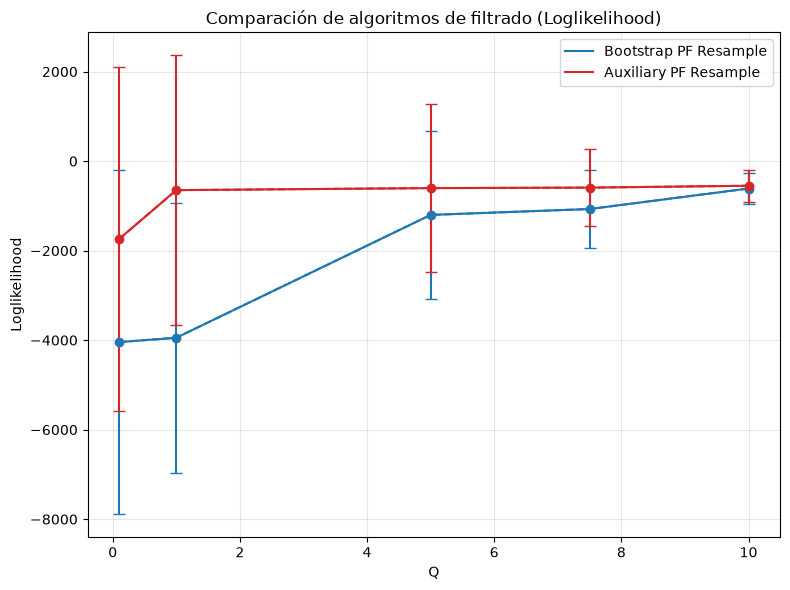

In [6]:
loglikelihood_bpf, loglikelihood_bpf_sim = calculate_loglikelihood(results_bpf)
loglikelihood_apf, loglikelihood_apf_sim = calculate_loglikelihood(results_apf)

# Media para cada q
res_loglikelihood_bpf = [ np.mean(loglikelihood_bpf_sim[q]) for q in Q]
res_loglikelihood_apf = [ np.mean(loglikelihood_apf_sim[q]) for q in Q]

# STD para cada q
std_loglikelihood_bpf = [np.std(loglikelihood_bpf_sim[q], ddof=1) for q in Q]
std_loglikelihood_apf = [np.std(loglikelihood_bpf_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "Q": Q, "Loglikelihood": res_loglikelihood_bpf, "Loglikelihood_errorbars": std_loglikelihood_bpf }, 
        "Auxiliary PF Resample": { "Q": Q, "Loglikelihood": res_loglikelihood_apf, "Loglikelihood_errorbars": std_loglikelihood_apf}, 
    }, "Q", "Loglikelihood", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (ESS/N)'}, xlabel='Q', ylabel='ESS/N'>)

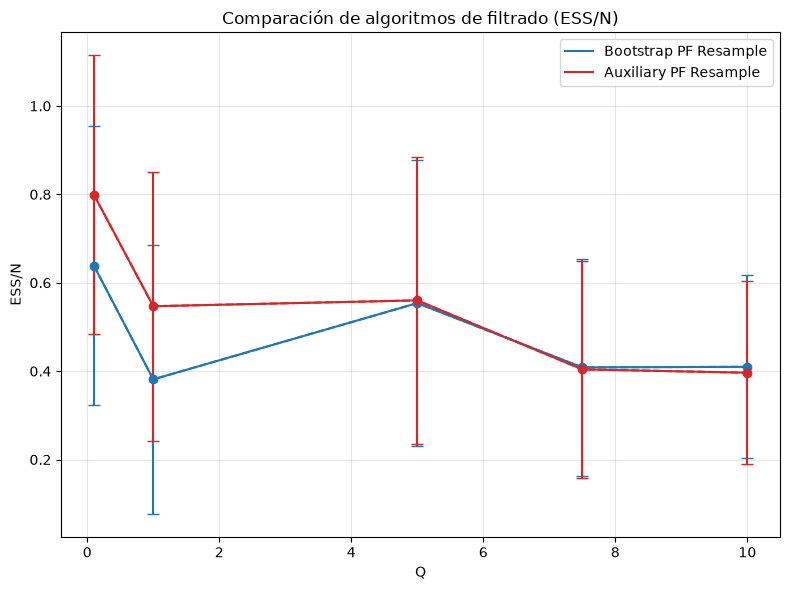

In [7]:
ess_bpf = calculate_mean_ess(results_bpf)
ess_apf = calculate_mean_ess(results_apf)

# Media para cada q
res_ess_bpf = [ np.mean(ess_bpf[q]) for q in Q]
res_ess_apf = [ np.mean(ess_apf[q]) for q in Q]

# STD para cada q
std_ess_bpf = [np.std(ess_bpf[q], ddof=1) for q in Q]
std_ess_apf = [np.std(ess_bpf[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "Q": Q, "ESS/N": res_ess_bpf, "ESS/N_errorbars": std_ess_bpf }, 
        "Auxiliary PF Resample": { "Q": Q, "ESS/N": res_ess_apf, "ESS/N_errorbars": std_ess_apf }, 
    }, "Q", "ESS/N", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (IC)'}, xlabel='Q', ylabel='IC'>)

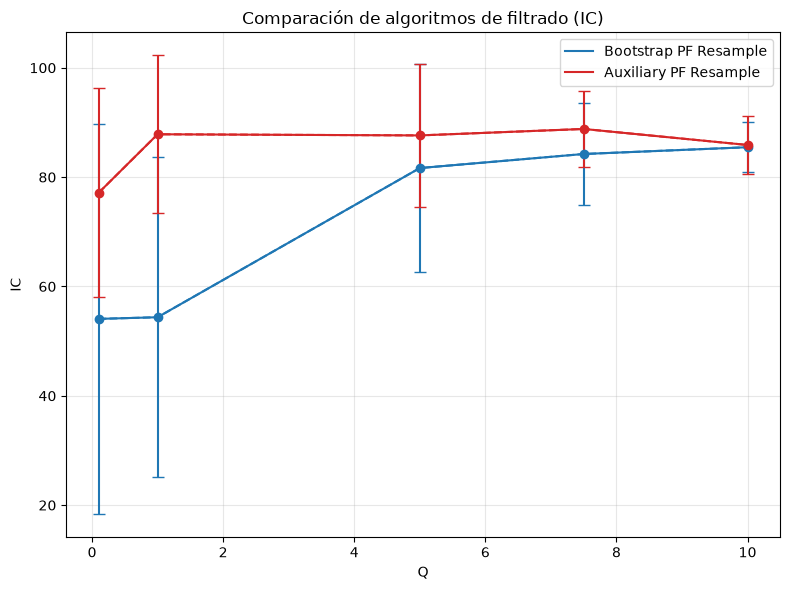

In [8]:
IC_bpf, IC_bpf_sim = calculate_mean_IC(results_bpf, Interval_cover)
IC_apf, IC_apf_sim = calculate_mean_IC(results_apf, Interval_cover)

# Media para cada q
res_IC_bpf = [ np.mean(IC_bpf_sim[q]) for q in Q]
res_IC_apf = [ np.mean(IC_apf_sim[q]) for q in Q]

# STD para cada q
std_IC_bpf = [np.std(IC_bpf_sim[q], ddof=1) for q in Q]
std_IC_apf = [np.std(IC_apf_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "Q": Q, "IC": res_IC_bpf, "IC_errorbars": std_IC_bpf }, 
        "Auxiliary PF Resample": { "Q": Q, "IC": res_IC_apf, "IC_errorbars": std_IC_apf }, 
    }, "Q", "IC", True
)

### Variación del número de partículas

Ahora se va a tomar el caso en el que $Q=1.0$ y $R=1.0$ y se va a modificar el número de partículas. En ambos casos el criterio de remustreo es el mismo que en la sección anterior.

In [13]:
import pickle

#--------------
# ONFIGURACIÓN
#--------------

# Longitud de la simulacion
T = 100

# Estado inicial
x0 = np.array([[0.0]])

# Valores matriz covarianza de transición
N = [25, 50, 100, 250, 500, 1000]

# Numero de simulaciones
n_simulations = 5

# Numero ejecuciones filtro
n_runs = 5

#--------------------------------------
# MODELOS DE TRANSICION Y OBSERVACION
#--------------------------------------
Q = R = np.array([[1.]])
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

#--------------
# RESULTADOS
#--------------
results_bpf = []
results_apf = []


for n in N:

    # Lista de simulaciones para N
    n_results_bpf = []
    n_results_apf = []


    #---------------------------------------------
    # 'n_simulations' SIMULACIONES INDEPENDIENTES
    #---------------------------------------------

    for simulation in range(n_simulations):

        # Simulacion
        x_true, y_obs = system_simulation(transition, observation, x0, T)

        # Lista para 'n_runs' filtrados
        simulation_bpf = []
        simulation_apf = []

        #------------------------------
        # 'n_runs' EJECUCIONES FILTRO
        #------------------------------

        for run in range(n_runs):

            # Ejecucion Bootstrap Particle Filter
            bpf = BootstrapParticleFilter(N=n, transition_model=transition, observation_model=observation)
            bpf.initialize(mean=np.array([0.0]), cov = np.eye(1))
            est_bpf = bpf.run_filter(y_obs, resample_threshold=(bpf.N - 1))

            est_bpf["run"] = run
            simulation_bpf.append(est_bpf)

            # Ejecucion Auxiliary Particle Filter
            apf = AuxiliaryParticleFilter(N=n, transition_model=transition, observation_model=observation)
            apf.initialize(mean=np.array([0.0]), cov = np.eye(1))
            est_apf = apf.run_filter(y_obs, resample_threshold=(apf.N - 1))

            est_apf["run"] = run
            simulation_apf.append(est_apf)

        #---------------------
        # GUARDAR SIMULACION
        #---------------------

        simulation_result_bpf = {
            "N": n,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_bpf
        }

        simulation_result_apf = {
            "N": n,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_apf
        }

        n_results_bpf.append(simulation_result_bpf)
        n_results_apf.append(simulation_result_apf)


    #-------------------------------
    # GUARDAR RESULTADOS DE ESTE Q
    #-------------------------------
    
    results_bpf.append(n_results_bpf)
    results_apf.append(n_results_apf)

    print(f"Matriz {n} finalizado")        


#-------------------------------
# GUARDAR RESULTADOS DE ESTE Q
#-------------------------------

with open("results_bpf_exp2.pkl", "wb") as file:
    pickle.dump(results_bpf, file)

with open("results_apf_exp2.pkl", "wb") as file:
    pickle.dump(results_apf, file)


Matriz 25 finalizado
Matriz 50 finalizado
Matriz 100 finalizado
Matriz 250 finalizado
Matriz 500 finalizado
Matriz 1000 finalizado


In [5]:
# Importar resultados
import pickle

with open('results_bpf_exp2.pkl', 'rb') as file:
    results_bpf = pickle.load(file)

with open('results_apf_exp2.pkl', 'rb') as file:
    results_apf = pickle.load(file)

In [3]:
from functions_experiment2 import calculate_rmse, calculate_loglikelihood, calculate_mean_ess, calculate_mean_IC

In [7]:
N = [25, 50, 100, 250, 500, 1000]


(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (RMSE)'}, xlabel='N', ylabel='RMSE'>)

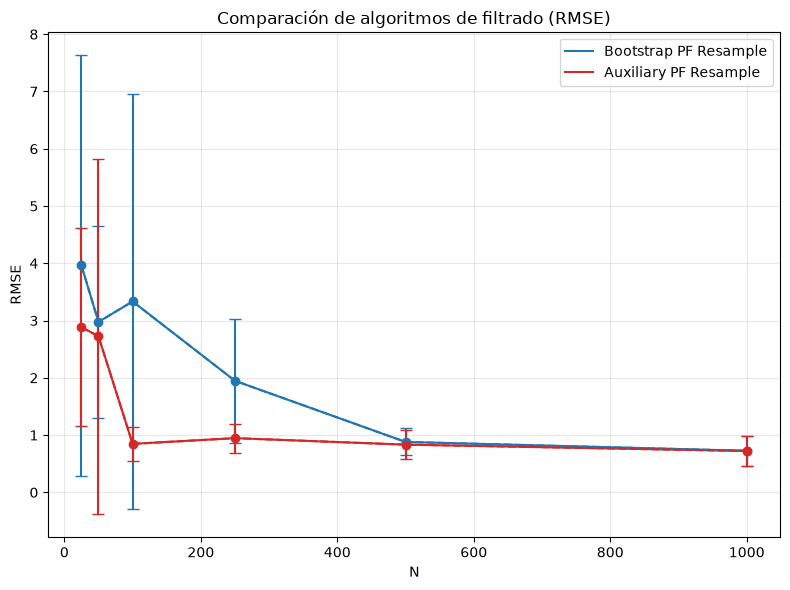

In [8]:
rmse_bpf, rmse_bpf_sim = calculate_rmse(results_bpf)
rmse_apf, rmse_apf_sim = calculate_rmse(results_apf)

# Media de 'n_simulations' para cada n
res_rmse_bpf = [ np.mean(rmse_bpf_sim[n]) for n in N]
res_rmse_apf = [ np.mean(rmse_apf_sim[n]) for n in N]

# STD para cada q
std_rmse_bpf = [np.std(rmse_bpf_sim[n], ddof=1) for n in N]
std_rmse_apf = [np.std(rmse_apf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "N": N, "RMSE": res_rmse_bpf, "RMSE_errorbars": std_rmse_bpf }, 
        "Auxiliary PF Resample": { "N": N, "RMSE": res_rmse_apf, "RMSE_errorbars": std_rmse_apf }, 
    }, "N", "RMSE", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (Loglikelihood)'}, xlabel='N', ylabel='Loglikelihood'>)

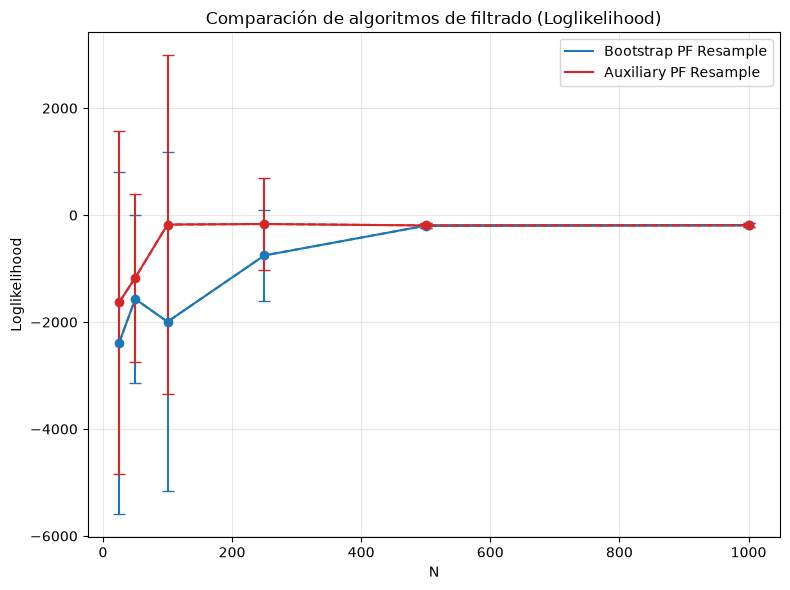

In [11]:
loglikelihood_bpf, loglikelihood_bpf_sim = calculate_loglikelihood(results_bpf)
loglikelihood_apf, loglikelihood_apf_sim = calculate_loglikelihood(results_apf)

# Media para cada q
res_loglikelihood_bpf = [ np.mean(loglikelihood_bpf_sim[n]) for n in N]
res_loglikelihood_apf = [ np.mean(loglikelihood_apf_sim[n]) for n in N]

# STD para cada q
std_loglikelihood_bpf = [np.std(loglikelihood_bpf_sim[n], ddof=1) for n in N]
std_loglikelihood_apf = [np.std(loglikelihood_bpf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "N": N, "Loglikelihood": res_loglikelihood_bpf, "Loglikelihood_errorbars": std_loglikelihood_bpf }, 
        "Auxiliary PF Resample": { "N": N, "Loglikelihood": res_loglikelihood_apf, "Loglikelihood_errorbars": std_loglikelihood_apf}, 
    }, "N", "Loglikelihood", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (ESS/N)'}, xlabel='N', ylabel='ESS/N'>)

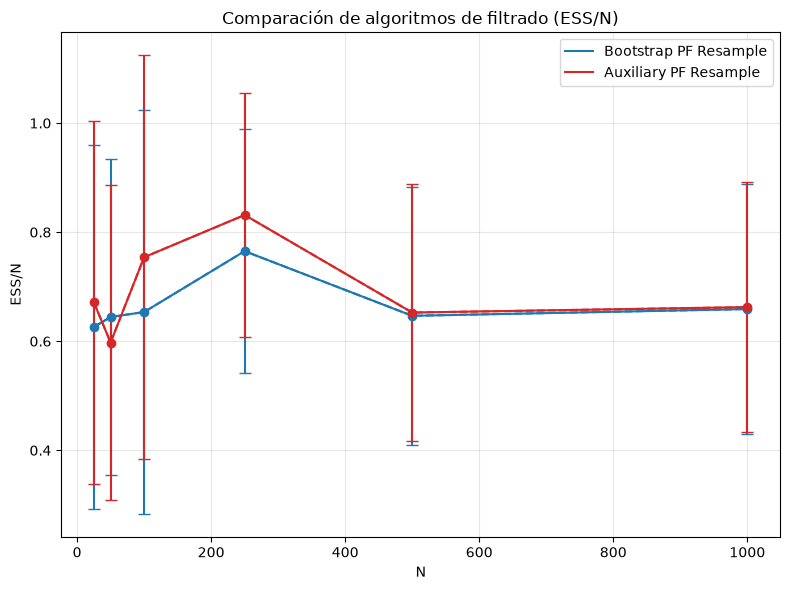

In [13]:
ess_bpf = calculate_mean_ess(results_bpf)
ess_apf = calculate_mean_ess(results_apf)

# Media para cada q
res_ess_bpf = [ np.mean(ess_bpf[n]) for n in N]
res_ess_apf = [ np.mean(ess_apf[n]) for n in N]

# STD para cada q
std_ess_bpf = [np.std(ess_bpf[n], ddof=1) for n in N]
std_ess_apf = [np.std(ess_bpf[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "N": N, "ESS/N": res_ess_bpf, "ESS/N_errorbars": std_ess_bpf }, 
        "Auxiliary PF Resample": { "N": N, "ESS/N": res_ess_apf, "ESS/N_errorbars": std_ess_apf }, 
    }, "N", "ESS/N", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (IC)'}, xlabel='N', ylabel='IC'>)

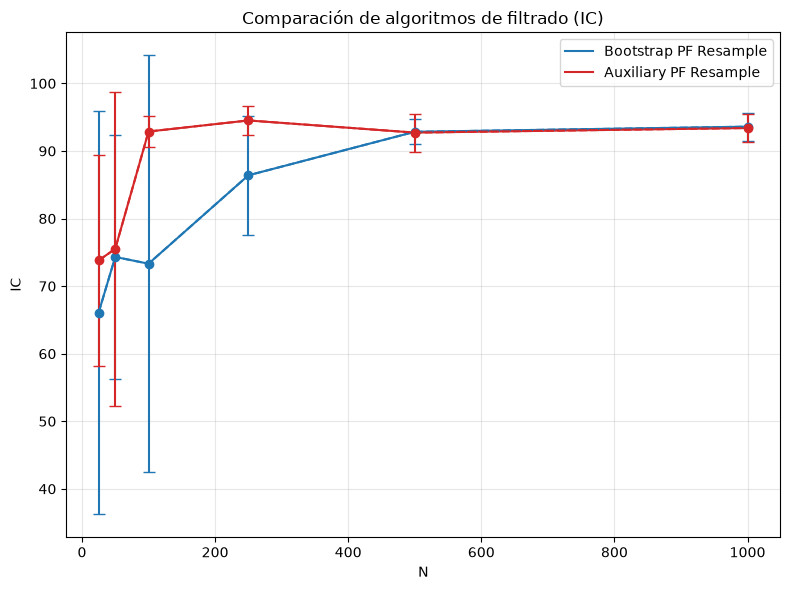

In [14]:
IC_bpf, IC_bpf_sim = calculate_mean_IC(results_bpf, Interval_cover)
IC_apf, IC_apf_sim = calculate_mean_IC(results_apf, Interval_cover)

# Media para cada q
res_IC_bpf = [ np.mean(IC_bpf_sim[n]) for n in N]
res_IC_apf = [ np.mean(IC_apf_sim[n]) for n in N]

# STD para cada q
std_IC_bpf = [np.std(IC_bpf_sim[n], ddof=1) for n in N]
std_IC_apf = [np.std(IC_apf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "N": N, "IC": res_IC_bpf, "IC_errorbars": std_IC_bpf }, 
        "Auxiliary PF Resample": { "N": N, "IC": res_IC_apf, "IC_errorbars": std_IC_apf }, 
    }, "N", "IC", True
)